In [22]:
import pandas as pd

# 1. Read the CSV file into the pandas dataframe
bicycle = pd.read_csv("bicycle_data.csv") 
bicycle # looking at the columns in the dataframe
bicycle.dtypes # checking the data types of the columns in the dataframe

# 2. In a comment, describe the columns in the datafram and what data types they should be.
# The dataframe has four columns. 
# The first is the date and time, this should be represented by a "datetime" object, but is currently represented by strings. 
# The second is the total number of bicycles counted at that timepoint on the Fremont Bridge Sidewalks, south of N 34th St.
# The third is the number of bicycles counted at that timepoint on the West Sidewalk at the above location 
# The fourth is the number of bicycles counted at that timepoint on the East Sidewalk at the above location 
# The second, third, and fourth columns should be represented by integers, but are currently represented by decimal numbers (float64)

# 2 (cont). If the data types in the dataframe do not match what you think they should be, update them.
# changing column 1 to datetime
bicycle["Date"] = pd.to_datetime(bicycle["Date"])
# changing column 2 to integers
bicycle["Fremont Bridge Sidewalks, south of N 34th St Total"] = bicycle["Fremont Bridge Sidewalks, south of N 34th St Total"].astype("Int64")
# changing column 3 to integers
bicycle["Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"] = bicycle["Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"].astype("Int64")
# changing column 4 to integers
bicycle["Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"] = bicycle["Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"].astype("Int64")
bicycle.dtypes # checking that the data types changed correctly

/var/folders/cn/kw4dgn5x4dx7pyxpnv1bslvm0000gn/T/ipykernel_93551/2582015789.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  bicycle["Date"] = pd.to_datetime(bicycle["Date"])


Date                                                                  datetime64[us]
Fremont Bridge Sidewalks, south of N 34th St Total                             Int64
Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk             Int64
Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk             Int64
dtype: object

In [27]:
# 3. Add columns to the dataframe containing:
# (a) The total (East + West) bicycle count
bicycle["Total (East + West) Bicycle Count"] = bicycle["Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"] + bicycle["Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"]

# (b) The hour of the day
bicycle["Hour of the Day"] = bicycle["Date"].dt.hour

# (c) The year
bicycle["Year"] = bicycle["Date"].dt.year

bicycle # checking that the columns got added correctly

Date                                                                  datetime64[us]
Fremont Bridge Sidewalks, south of N 34th St Total                             Int64
Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk             Int64
Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk             Int64
Total (East + West) Bicycle Count                                              Int64
Hour of the Day                                                                int32
Year                                                                           int32
dtype: object

In [30]:
# 4. Create a new dataframe with the subset of data from the year 2016
bicycle_2016 = bicycle[bicycle["Year"] == 2016]
bicycle_2016 

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk",Total (East + West) Bicycle Count,Hour of the Day,Year
28451,2016-01-01 00:00:00,18,9,9,18,0,2016
28452,2016-01-01 01:00:00,15,12,3,15,1,2016
28453,2016-01-01 02:00:00,11,5,6,11,2,2016
28454,2016-01-01 03:00:00,7,6,1,7,3,2016
28455,2016-01-01 04:00:00,2,2,0,2,4,2016
...,...,...,...,...,...,...,...
37230,2016-12-31 19:00:00,10,4,6,10,19,2016
37231,2016-12-31 20:00:00,9,6,3,9,20,2016
37232,2016-12-31 21:00:00,10,6,4,10,21,2016
37233,2016-12-31 22:00:00,15,8,7,15,22,2016


In [40]:
# 5. For the dataframe you created in 4, are there any time points with missing data?
# If so, do something to make sure missing data does not impact parts 6 and 7

# dropping any time points with missing data from the 2016 dataframe
bicycle_2016_no_na = bicycle_2016.dropna()

# checking how many time points were in the original 2016 dataframe
bicycle_2016.shape # 8784
# checking how many time points are in the new 2016 dataframe after missing points were removed
bicycle_2016_no_na.shape # 8783
# there was one time point with missing data

(8783, 7)

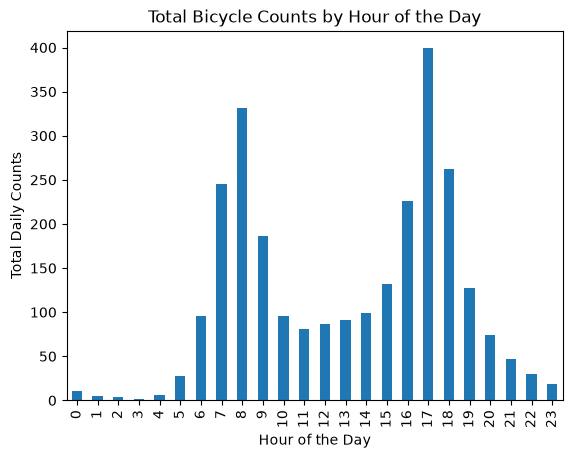

In [65]:
# 6. For the dataframe you created in 4, use pandas + matplotlib to plot the counts by hour
# (i.e. hour of the day on the x-axis, total daily counts on the y-axis).
# Add an appropriate title and name the axes and save the image to a file called counts_by_hour.png
import matplotlib.pyplot as plt

# create a dataframe with just the total count and the hour of the day to plot 
# calculate the mean grouped by the hour of the day
plot_data = bicycle_2016_no_na[["Total (East + West) Bicycle Count", "Hour of the Day"]].groupby("Hour of the Day").mean()

# create the plot as a bar chart to clearly show counts by hour
plot_data.plot.bar(title = "Total Bicycle Counts by Hour of the Day", xlabel = "Hour of the Day", ylabel = "Total Daily Counts", legend = False)

# save the plot
plt.savefig("counts_by_hour.png")

In [68]:
# 7. For the dataframe you created in 4, use python (and pandas) programming 
# to computationally determine what is (on average) the busiest hour of the day

# creating a table with the mean bicycle count for each hour of the day to determine the busiest hour on average
bicycle_2016_no_na[["Total (East + West) Bicycle Count", "Hour of the Day"]].groupby("Hour of the Day").mean()

# the busiest hour of the day is 17:00, or 5:00pm, with an average total bicycle count of 399

,Total (East + West) Bicycle Count
Hour of the Day,
0,10.68306
1,5.532787
2,3.465753
3,2.13388
4,6.120219
5,27.743169
6,95.306011
7,244.874317
8,331.797814
